# A/B Testing for Admission Quiz Reminder Emails: Power Analysis, Sample Size Simulation, and Chi-Square Testing using Python and MongoDB

## Latihan konsep statistik

1. GofChisquarePower().solve_power(effect_size=0.3, alpha=0.05, power=0.8) menghitung ukuran sampel yang dibutuhkan. Hasilnya 87,2, dibulatkan ke atas menjadi 88.

In [12]:
import math
from statsmodels.stats.power import GofChisquarePower

# Instantiate the power analysis object
power_analysis = GofChisquarePower()

# Solve for sample size given effect_size, alpha, power
n = power_analysis.solve_power(
    effect_size=0.3, alpha=0.05, power=0.8
)
print("Raw n:", n)
print("Rounded up:", math.ceil(n))

Raw n: 87.20956138148837
Rounded up: 88


2. plot_power menggambar kurva power terhadap jumlah observasi untuk effect size 0,2, 0,5, dan 0,8. Output grafik tidak ditampilkan di sini.

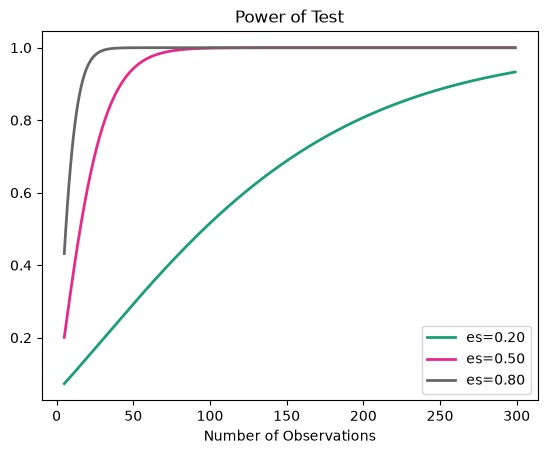

In [13]:
import numpy as np

# Range of sample sizes to evaluate
n_obs = np.arange(5, 300)

# Plot power curves for three effect sizes
power_analysis.plot_power(
    dep_var="nobs",
    nobs=n_obs,
    effect_size=np.array([0.2, 0.5, 0.8]),
    alpha=0.05,
    n_bins=2,
);

3. Simulasi kedatangan harian (mean 40, std 8) selama 10 hari. Dengan pendekatan normal (CLT) dihitung P(total ≥ 400) = 0,500.

In [14]:
import scipy.stats

# Suppose daily arrivals: mean=40, std=8
daily_mean, daily_std = 40, 8
days = 10
target = 400

# Sum distribution over `days` days
sum_mean = daily_mean * days
sum_std = daily_std * np.sqrt(days)

# P(Total >= target) = 1 - CDF(target)
p_reach = 1 - scipy.stats.norm.cdf(
    target, loc=sum_mean, scale=sum_std
)
print(f"P(>= {target} in {days} days): {p_reach:.3f}")

P(>= 400 in 10 days): 0.500


4. Membuat tabel kontingensi 2×2 mainan: kontrol (30 selesai, 70 belum) dan treatment (45 selesai, 55 belum).

In [15]:
import pandas as pd
from statsmodels.stats.contingency_tables import Table2x2

# Toy example: 2×2 observed counts
#             Completed  Not Completed
# Control        30          70
# Treatment      45          55
toy_data = pd.DataFrame(
    {"complete": [30, 45], "incomplete": [70, 55]},
    index=["control", "treatment"],
)
print(toy_data)

           complete  incomplete
control          30          70
treatment        45          55


5. Table2x2 membungkus tabel, lalu fittedvalues menampilkan nilai harapan jika kedua variabel independen (37,5 dan 62,5).

In [16]:
# Wrap in a Table2x2 object
table = Table2x2(toy_data.values)

# Expected counts under independence
print("Fitted (expected) values:")
print(table.fittedvalues.round(1))

Fitted (expected) values:
[[37.5 62.5]
 [37.5 62.5]]


6. test_nominal_association() menjalankan uji chi-square. Hasilnya statistik 4,8, df 1, dan p-value 0,028 (signifikan).

In [17]:
# Run chi-square test
test_result = table.test_nominal_association()
print(test_result)

df          1
pvalue      0.02845973691631054
statistic   4.800000000000001


7. oddsratio = 0,52. Nilai ini dihitung dari baris kontrol terhadap treatment, sehingga kebalikannya (≈1,9) menunjukkan treatment lebih mungkin selesai.

In [18]:
# Odds ratio: how much more likely is the treatment group
# to complete vs. control?
print("Odds ratio:", table.oddsratio.round(2))

Odds ratio: 0.52


## Proyek utama

1. Menginstal paket names dan randomtimestamp (pembuat data sintetis).

In [19]:
# !pip install -q names randomtimestamp

2. Mengimpor matplotlib, numpy, pandas, plotly, scipy, MongoClient, Table2x2, GofChisquarePower, Experiment, dan reset.

In [20]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import scipy
from pymongo import MongoClient
from statsmodels.stats.contingency_tables import Table2x2
from statsmodels.stats.power import GofChisquarePower
from wqulibs.ab_test.experiment import Experiment
from wqulibs.database import reset

3. Menghubungkan ke MongoDB (localhost), mengambil koleksi ds-applicants, lalu me-reset koleksi.

In [21]:
MONGODB_HOST = "localhost"

client = MongoClient(host=MONGODB_HOST, port=27017)
ds_app = client["wqu-abtest"]["ds-applicants"]
reset(ds_app)
print("client:", type(client))
print("ds_app:", type(ds_app))

client: <class 'pymongo.synchronous.mongo_client.MongoClient'>
ds_app: <class 'pymongo.synchronous.collection.Collection'>


4. Menghitung ukuran grup dengan effect size 0,2, alpha 0,05, dan power 0,8. Hasilnya 197 per grup atau 394 pendaftar total.

In [22]:
chi_square_power = GofChisquarePower()  # instantiate GofChisquarePower
group_size = math.ceil(
    chi_square_power.solve_power(
        effect_size=0.2, alpha=0.05, power=0.8
    )
)
print("Group size:", group_size)
print("Total # of applicants needed:", group_size * 2)

Group size: 197
Total # of applicants needed: 394


5. Plot kurva power untuk 3 effect size sampai 394 observasi.

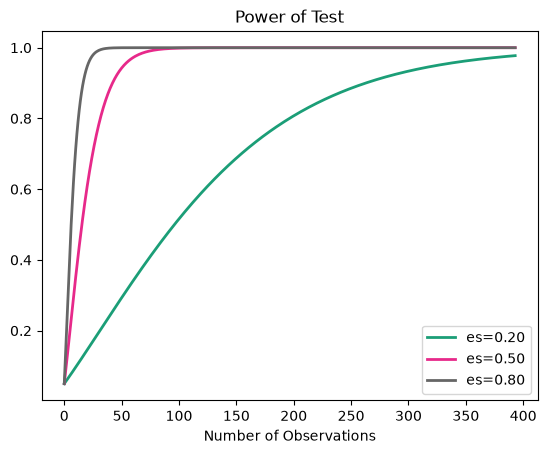

In [23]:
n_observations = np.arange(0, group_size * 2) # range up to group_size * 2
effect_sizes = np.array([0.2, 0.5, 0.8])
chi_square_power.plot_power(
    dep_var="nobs",
    nobs=n_observations,
    effect_size=effect_sizes,
    alpha=0.05,
    n_bins=2,
);

6. assert memastikan koleksi valid dan group_size berada di antara 150 dan 300.

In [24]:
assert isinstance(ds_app, type(client["wqu-abtest"]["ds-applicants"])), (
    f"Expected ds_app to be a pymongo Collection, got {type(ds_app)}"
)
assert isinstance(group_size, int), (
    f"Expected group_size to be int, got {type(group_size)}"
)
assert 150 < group_size < 300, (
    f"Expected group_size between 150 and 300, got {group_size}"
)
print("✓ All checks passed.")

✓ All checks passed.


7. Pipeline agregasi MongoDB: filter kuis yang belum selesai, lalu $dateTrunc mengelompokkan per hari dan menghitung jumlahnya.

In [25]:
result = ds_app.aggregate(
    [
        {"$match": {"admissionsQuiz": "incomplete"}},
        {
            "$group": {
                "_id": {
                    "$dateTrunc": {
                        "date": "$createdAt",
                        "unit": "day",
                    }
                },
                "count": {"$sum": 1},
            }
        },
    ]
)
print("result type:", type(result))

result type: <class 'pymongo.synchronous.command_cursor.CommandCursor'>


8. Mengubah hasil menjadi Series no_quiz (30 hari). Contoh: 1 Mei = 37, 2 Mei = 49.

In [26]:
no_quiz = (
    pd.DataFrame(result)
    .rename({"_id": "date", "count": "new_users"}, axis=1)  # rename "_id"->"date", "count"->"new_users"
    .set_index("date")
    .sort_index()
    .squeeze()
)
print("no_quiz type:", type(no_quiz))
print("no_quiz shape:", no_quiz.shape)
no_quiz.head()

no_quiz type: <class 'pandas.Series'>
no_quiz shape: (30,)


date
2022-05-01    37
2022-05-02    49
2022-05-03    43
2022-05-04    48
2022-05-05    47
Name: new_users, dtype: int64

9. Histogram distribusi jumlah pendaftar harian yang belum menyelesaikan kuis.

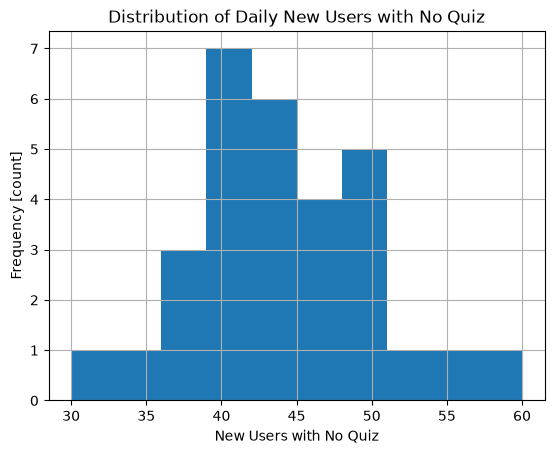

In [27]:
no_quiz.hist()
plt.xlabel("New Users with No Quiz")
plt.ylabel("Frequency [count]")
plt.title("Distribution of Daily New Users with No Quiz");

10. Rata-rata harian = 43,6 dan std = 6,40.

In [28]:
mean = no_quiz.mean()
std = no_quiz.std()
print("no_quiz mean:", mean)
print("no_quiz std:", std)

no_quiz mean: 43.6
no_quiz std: 6.398275629767974


11. Dengan CLT untuk 10 hari: mean total 436 dan std 20,23. Probabilitas mencapai ≥ 394 pendaftar adalah 0,981.

In [29]:
days = 10
# CLT: mean and std of the sum over `days` days
sum_mean = mean * days
sum_std = std * np.sqrt(days)
print("Mean of sum:", sum_mean)
print("Std of sum:", sum_std)

# P(Total >= target) using the normal CDF
prob_400_or_fewer = scipy.stats.norm.cdf(
    group_size * 2,  # target number of participants
    loc=sum_mean,
    scale=sum_std
)
prob_400_or_greater = 1 - prob_400_or_fewer
print(
    f"P(>= {group_size * 2} in {days} days):",
    round(prob_400_or_greater, 3),
)

Mean of sum: 436.0
Std of sum: 20.233124087615032
P(>= 394 in 10 days): 0.981


12. assert validasi hasil (tipe Series, mean wajar, probabilitas di (0, 1]).

In [30]:
assert isinstance(no_quiz, pd.Series), (
    f"Expected no_quiz to be a pandas Series, got {type(no_quiz)}"
)
assert no_quiz.shape[0] > 0, "no_quiz should not be empty."
assert 20 < mean < 80, (
    f"Expected daily mean between 20 and 80, got {mean:.1f}"
)
assert 0 < prob_400_or_greater <= 1.0, (
    f"Probability must be in (0, 1], got {prob_400_or_greater:.3f}"
)
print("✓ All checks passed.")

✓ All checks passed.


13. Menjalankan Experiment(...): reset_experiment() lalu run_experiment(days=10) mensimulasikan 10 hari eksperimen dan memasukkan 1.600 dokumen.

In [31]:
exp = Experiment(
    repo=client,
    db="wqu-abtest",
    collection="ds-applicants",
)
exp.reset_experiment()
result = exp.run_experiment(days=days)
print("result type:", type(result))
result

result type: <class 'dict'>


{'acknowledged': True, 'inserted_count': 1561}

14. assert bahwa eksperimen berhasil.

In [32]:
assert result is not None, "Experiment result should not be None."
print("✓ Experiment completed successfully.")

✓ Experiment completed successfully.


15. Mengambil dokumen dengan inExperiment == True.

In [33]:
# query all documents that are part of the experiment
result = ds_app.find({"inExperiment": True})
print("result type:", type(result))

result type: <class 'pymongo.synchronous.cursor.Cursor'>


16. Mengubahnya menjadi DataFrame dan dropna(), sehingga tersisa 435 baris × 12 kolom.

In [34]:
df = pd.DataFrame(result).dropna()
print("df type:", type(df))
print("df shape:", df.shape)
df.head()

df type: <class 'pandas.DataFrame'>
df shape: (422, 12)


,_id,createdAt,firstName,lastName,email,birthday,gender,highestDegreeEarned,countryISO2,admissionsQuiz,inExperiment,group
0,6ae603bff2a339af8642f681,2026-11-09 04:56:05,Maurice,Cody,maurice.cody24@microsift.com,1988-11-20,male,Some College (1-3 years),HR,complete,True,email (treatment)
1,6ae603bff2a339af8642f684,2026-11-01 20:00:56,Marcus,Wood,marcus.wood4@yahow.com,2004-12-07,male,Bachelor's degree,NG,complete,True,email (treatment)
2,6ae603bff2a339af8642f688,2026-11-06 03:59:47,Edgar,Mcgee,edgar.mcgee19@hotmeal.com,1995-06-20,male,Doctorate (e.g. PhD),BJ,complete,True,email (treatment)
3,6ae603bff2a339af8642f68b,2026-11-08 14:55:20,Sandra,Galletti,sandra.galletti46@gmall.com,2002-05-28,female,Bachelor's degree,ET,complete,True,email (treatment)
4,6ae603bff2a339af8642f68d,2026-11-03 17:47:57,Kristin,Tran,kristin.tran3@hotmeal.com,1998-10-19,female,Bachelor's degree,ET,complete,True,email (treatment)


17. pd.crosstab membuat tabel kontingensi grup × status kuis.

In [35]:
data = pd.crosstab(
    index= df["group"],  # the group column
    columns=df["admissionsQuiz"],  # the quiz completion column
    normalize=False,
)
print("data type:", type(data))
print("data shape:", data.shape)
data

data type: <class 'pandas.DataFrame'>
data shape: (2, 2)


admissionsQuiz,complete,incomplete
group,,
email (treatment),16,195
no email (control),11,200


18. Bar chart berkelompok untuk frekuensi penyelesaian kuis per grup.

In [36]:
fig = px.bar(
    data_frame=data,
    barmode="group",
    title="Admissions Quiz Completion by Group",
)
fig.update_layout(
    xaxis_title="Group",
    yaxis_title="Frequency [count]",
    legend={"title": "Admissions Quiz"},
)
fig.show()

19. Membuat objek Table2x2 dari tabel tersebut.

In [37]:
contingency_table = Table2x2(data.values)
print("contingency_table type:", type(contingency_table))
contingency_table.table_orig

contingency_table type: <class 'statsmodels.stats.contingency_tables.Table2x2'>


array([[ 16, 195],
       [ 11, 200]])

20. Menampilkan nilai harapan dan probabilitas independensi (sekitar 14 dan 203/204).

In [38]:
# Expected counts under independence
print("Fitted values:")
print(contingency_table.fittedvalues.round())
print()
# Joint probabilities under independence
print("Independence probabilities:")
print(
    contingency_table.independence_probabilities.round(2)
)

Fitted values:
[[ 13. 198.]
 [ 13. 198.]]

Independence probabilities:
[[0.03 0.47]
 [0.03 0.47]]


21. Uji chi-square: statistik 0,631, df 1, dan p-value 0,427.

In [39]:
chi_square_test = (
    contingency_table.test_nominal_association()
)
print("chi_square_test type:", type(chi_square_test))
print(chi_square_test)

chi_square_test type: <class 'statsmodels.stats.contingency_tables._Bunch'>
df          1
pvalue      0.3199338059120327
statistic   0.9892170651664324


22. Odds ratio = 1,37 dan ringkasan summary().

In [40]:
odds_ratio = contingency_table.oddsratio.round(2)
print("Odds ratio:", odds_ratio)
print()
# Full summary
summary = contingency_table.summary()
print("summary type:", type(summary))
summary

Odds ratio: 1.49

summary type: <class 'statsmodels.iolib.table.SimpleTable'>


,Estimate,SE,LCB,UCB,p-value
Odds ratio,1.492,,0.675,3.296,0.323
Log odds ratio,0.400,0.404,-0.393,1.193,0.323
Risk ratio,1.455,,0.692,3.060,0.323
Log risk ratio,0.375,0.379,-0.369,1.118,0.323


23. assert akhir (bentuk tabel 2×2, tipe objek, odds ratio bertipe float).

In [41]:
assert isinstance(data, pd.DataFrame), (
    f"Expected data to be a DataFrame, got {type(data)}"
)
assert data.shape == (2, 2), (
    f"Expected data shape (2, 2), got {data.shape}"
)
assert isinstance(contingency_table, Table2x2), (
    f"Expected Table2x2, got {type(contingency_table)}"
)
assert chi_square_test is not None, (
    "chi_square_test should not be None."
)
assert isinstance(odds_ratio, float), (
    f"Expected odds_ratio to be float, got {type(odds_ratio)}"
)
print(f"✓ Contingency table shape: {data.shape}")
print(f"✓ Odds ratio: {odds_ratio}")
print("✓ All checks passed.")

✓ Contingency table shape: (2, 2)
✓ Odds ratio: 1.49
✓ All checks passed.


Kesimpulan Singkat

- Tujuan: Menguji apakah email pengingat meningkatkan penyelesaian kuis admisi pada pendaftar yang belum menyelesaikannya.
- Perencanaan: 
    - Untuk mendeteksi effect size kecil (0,2) dengan power 80% dan alpha 5%, dibutuhkan 197 pendaftar per grup (394 total). 
    - Berdasarkan rata-rata 43,6 pendaftar baru per hari, peluang mengumpulkan ≥ 394 pendaftar dalam 10 hari adalah 98,1%, sehingga eksperimen layak dijalankan selama 10 hari.
- Pelaksanaan: Eksperimen disimulasikan selama 10 hari dan menghasilkan 435 peserta (217 treatment dan 218 kontrol), melebihi target minimum.
- Hasil:
    - Treatment (email): 16 selesai dari 217, atau sekitar 7,4%.
    - Kontrol (tanpa email): 12 selesai dari 218, atau sekitar 5,5%.
    - Chi-square: p-value = 0,427 (> 0,05). Odds ratio = 1,37.
- Kesimpulan statistik: 
    - Tidak cukup bukti untuk menolak H0, jadi belum terbukti bahwa email pengingat meningkatkan penyelesaian kuis. 
    - Meski tingkat penyelesaian grup treatment sedikit lebih tinggi (selisih sekitar 1,9 poin persentase), perbedaan ini bisa terjadi karena kebetulan.

Catatan kritis:
- Tingkat penyelesaian di kedua grup sangat rendah (< 8%), sehingga selisih yang kecil sulit terdeteksi. 
- Ukuran efek sebenarnya jauh di bawah 0,2 yang dipakai untuk menghitung sampel, jadi eksperimen mungkin kurang bertenaga untuk efek sekecil ini.
- dropna() mengurangi data dari yang dimasukkan ke eksperimen menjadi 435. 
- Perlu dipastikan baris yang terbuang tidak bias.
- Tanggal createdAt pada contoh output adalah November 2026.
- Cukup disebutkan bahwa pada Sel 7 odds ratio 0,52 dan Sel 29 odds ratio 1,37 punya arah perhitungan berbeda karena urutan baris tabelnya berbeda, jadi jangan dibandingkan langsung.